# 04 · Baseline: the floor and the references

SPEC 03, roadmap 4.1 (floor and references only). Train races only. This notebook sets the numbers that Phase 4
has to beat: the median dummy (the floor), the qualifying linear baseline of the contract, and a naive predictor
from domain knowledge (the driver's recent form). Tuning and the other models belong to Phase 4.

**Scoring.** MAE counting only valid rows, as the contract says. **Validation.** Expanding window over whole races
in order: `cv.folds` (5) blocks, fitting on the races before each block and scoring on the block. The first
races never enter a test block. Intervals resample races, with the seed of `config/training.json`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks" / "exploratory")]

from provisional import DATASET_PATH  # noqa: E402

from common.config import load_config  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False}
)
SEED = load_config().optuna.seed
rng = np.random.default_rng(SEED)
df = pd.read_parquet(DATASET_PATH)
valid = df[df["is_valid_row"]].copy()
n_races = valid[["year", "round"]].drop_duplicates().shape[0]
print(f"{len(df)} rows, {len(valid)} valid, {n_races} train races, seed {SEED}")
from sklearn.model_selection import TimeSeriesSplit  # noqa: E402


def race_bootstrap(stat, frame=None, draws=1000):
    """95% interval of `stat(frame)` resampling whole races, never single rows."""
    frame = valid if frame is None else frame
    key = frame["year"].astype(str) + "-" + frame["round"].astype(str)
    groups = [g.index.to_numpy() for _, g in frame.groupby(key)]
    values = []
    for _ in range(draws):
        pick = rng.integers(0, len(groups), len(groups))
        values.append(stat(frame.loc[np.concatenate([groups[i] for i in pick])]))
    return np.percentile(values, [2.5, 97.5]).round(3)


TARGET = "race_pace_delta_pct"
valid = valid.sort_values(["year", "round"]).reset_index(drop=True)
valid["quali_cap3"] = valid["quali_delta_pct"].clip(upper=3)
order = valid[["year", "round"]].drop_duplicates().reset_index(drop=True)
valid = valid.merge(order.reset_index(names="race"), on=["year", "round"])
folds = list(TimeSeriesSplit(n_splits=load_config().cv.folds).split(order))
for k, (train_races, test_races) in enumerate(folds, 1):
    first, last = order.iloc[test_races[0]], order.iloc[test_races[-1]]
    print(
        f"fold {k}: train on {len(train_races)} races, test on {len(test_races)} "
        f"({first['year']} R{first['round']} to {last['year']} R{last['round']})"
    )

1118 rows, 1050 valid, 56 train races, seed 42


fold 1: train on 11 races, test on 9 (2023 R12 to 2023 R20)
fold 2: train on 20 races, test on 9 (2023 R21 to 2024 R7)
fold 3: train on 29 races, test on 9 (2024 R8 to 2024 R16)
fold 4: train on 38 races, test on 9 (2024 R17 to 2025 R1)
fold 5: train on 47 races, test on 9 (2025 R2 to 2025 R10)


## 1. The predictors

- **Median dummy** (the floor): the median target of the training races.
- **Mean dummy**: the same with the mean, to see what the loss mismatch costs.
- **Qualifying baseline**: linear regression of the target on `quali_delta_pct`, as the contract defines it. Shown
  both on the raw gap and on the gap capped at 3% (the cap of the scope document, kept by `02`).
- **Driver form**: predict the driver's `driver_pace_last3` as it is; the training median where it is empty.
- **Team form**: the same with `team_pace_last3`.

In [2]:
def fit_predict(name, train, test):
    median = train[TARGET].median()
    if name == "median dummy":
        return np.full(len(test), median)
    if name == "mean dummy":
        return np.full(len(test), train[TARGET].mean())
    if name in ("qualifying baseline (raw gap)", "qualifying baseline (gap capped at 3%)"):
        column = "quali_delta_pct" if "raw" in name else "quali_cap3"
        slope, intercept = np.polyfit(train[column], train[TARGET], 1)
        return intercept + slope * test[column].to_numpy()
    if name == "driver form (driver_pace_last3)":
        return test["driver_pace_last3"].fillna(median).to_numpy()
    if name == "team form (team_pace_last3)":
        return test["team_pace_last3"].fillna(median).to_numpy()
    raise KeyError(name)


NAMES = [
    "median dummy",
    "mean dummy",
    "qualifying baseline (raw gap)",
    "qualifying baseline (gap capped at 3%)",
    "driver form (driver_pace_last3)",
    "team form (team_pace_last3)",
]


def cross_validate(frame):
    """Fold MAEs per predictor and the out-of-fold errors of every scored row."""
    fold_mae = {name: [] for name in NAMES}
    scored = []
    for train_races, test_races in folds:
        train, test = frame[frame["race"].isin(train_races)], frame[frame["race"].isin(test_races)].copy()
        for name in NAMES:
            error = test[TARGET].to_numpy() - fit_predict(name, train, test)
            fold_mae[name].append(np.abs(error).mean())
            test["abs_error: " + name] = np.abs(error)
        scored.append(test)
    return pd.DataFrame(fold_mae), pd.concat(scored, ignore_index=True)


fold_mae, scored = cross_validate(valid)
print(f"{len(scored)} rows scored out of {len(valid)} valid rows")
summary = pd.DataFrame(
    {
        "mean MAE": fold_mae.mean(),
        "sd over folds": fold_mae.std(ddof=0),
        "min fold": fold_mae.min(),
        "max fold": fold_mae.max(),
    }
)
print(summary.round(3).to_string())
print("\nMAE of each fold:")
print(fold_mae.round(3).T.to_string())

839 rows scored out of 1050 valid rows
                                        mean MAE  sd over folds  min fold  max fold
median dummy                               0.727          0.063     0.677     0.850
mean dummy                                 0.727          0.063     0.678     0.849
qualifying baseline (raw gap)              0.682          0.056     0.641     0.793
qualifying baseline (gap capped at 3%)     0.523          0.043     0.473     0.575
driver form (driver_pace_last3)            0.517          0.100     0.404     0.703
team form (team_pace_last3)                0.517          0.079     0.413     0.656

MAE of each fold:
                                            0      1      2      3      4
median dummy                            0.689  0.677  0.850  0.697  0.720
mean dummy                              0.689  0.678  0.849  0.697  0.721
qualifying baseline (raw gap)           0.651  0.641  0.793  0.659  0.664
qualifying baseline (gap capped at 3%)  0.575  0.480  0.57

In [3]:
firm_mae, firm_scored = cross_validate(valid[valid["clean_laps"] >= 15])
both = pd.DataFrame(
    {
        "all valid rows": fold_mae.mean(),
        "sd": fold_mae.std(ddof=0),
        "15+ clean laps": firm_mae.mean(),
        "sd (15+)": firm_mae.std(ddof=0),
    }
)
print(f"same, with the 15-clean-lap minimum that 02 suggests ({len(firm_scored)} rows scored):")
print(both.round(3).to_string())

same, with the 15-clean-lap minimum that 02 suggests (833 rows scored):
                                        all valid rows     sd  15+ clean laps  sd (15+)
median dummy                                     0.727  0.063           0.703     0.086
mean dummy                                       0.727  0.063           0.704     0.086
qualifying baseline (raw gap)                    0.682  0.056           0.667     0.083
qualifying baseline (gap capped at 3%)           0.523  0.043           0.511     0.039
driver form (driver_pace_last3)                  0.517  0.100           0.494     0.067
team form (team_pace_last3)                      0.517  0.079           0.493     0.048


## 2. How sure are the differences?

Pooled out-of-fold MAE with a 95% interval that resamples races, and the gain of the qualifying baseline over the
floor, which is the quantity every Phase 4 model will be judged by.

In [4]:
def pooled(name):
    return lambda f: f["abs_error: " + name].mean()


rows = []
for name in NAMES:
    low, high = race_bootstrap(pooled(name), scored, 500)
    rows.append({"predictor": name, "pooled MAE": scored["abs_error: " + name].mean(), "ci_low": low, "ci_high": high})
print(pd.DataFrame(rows).round(3).to_string(index=False))

base = "qualifying baseline (gap capped at 3%)"
for other in ("median dummy", "qualifying baseline (raw gap)", "driver form (driver_pace_last3)"):

    def gain(f, other=other):
        return (f["abs_error: " + other] - f["abs_error: " + base]).mean()

    low, high = race_bootstrap(gain, scored, 500)
    print(f"MAE of '{other}' minus MAE of the capped baseline: {gain(scored):+.3f} [{low:+.3f}, {high:+.3f}]")
print(
    "baseline MAE as a share of the floor:",
    round(scored["abs_error: " + base].mean() / scored["abs_error: median dummy"].mean(), 3),
)

                             predictor  pooled MAE  ci_low  ci_high
                          median dummy       0.727   0.660    0.817
                            mean dummy       0.727   0.656    0.804
         qualifying baseline (raw gap)       0.682   0.611    0.762
qualifying baseline (gap capped at 3%)       0.522   0.468    0.599
       driver form (driver_pace_last3)       0.516   0.452    0.596
           team form (team_pace_last3)       0.516   0.443    0.589
MAE of 'median dummy' minus MAE of the capped baseline: +0.205 [+0.170, +0.241]


MAE of 'qualifying baseline (raw gap)' minus MAE of the capped baseline: +0.160 [+0.126, +0.197]
MAE of 'driver form (driver_pace_last3)' minus MAE of the capped baseline: -0.007 [-0.052, +0.043]
baseline MAE as a share of the floor: 0.718


## 3. Where the baseline errs

Mean absolute error of the capped baseline out of fold, by team, circuit type, year, rain in qualifying and
qualifying position, next to the floor. Rows behind each cell are shown.

In [5]:
base_col, floor_col = "abs_error: " + base, "abs_error: median dummy"
scored["qualifying position"] = pd.cut(
    scored["grid_position"], [0, 5, 10, 15, 20], labels=["1-5", "6-10", "11-15", "16-20"]
)
for key in ("team", "circuit_type", "year", "rain_flag", "qualifying position"):
    table = scored.groupby(key, observed=True).agg(
        rows=(base_col, "size"), baseline=(base_col, "mean"), floor=(floor_col, "mean")
    )
    table["gain"] = table["floor"] - table["baseline"]
    print(table.round(3).to_string(), "\n")

                 rows  baseline  floor   gain
team                                         
Alpine             80     0.511  0.576  0.065
Aston Martin       83     0.395  0.460  0.065
Ferrari            88     0.537  0.891  0.354
Haas F1 Team       85     0.451  0.495  0.044
Kick Sauber        85     0.537  0.837  0.301
McLaren            87     0.560  1.000  0.440
Mercedes           88     0.473  0.695  0.222
RB                 83     0.518  0.544  0.026
Red Bull Racing    83     0.539  0.935  0.396
Williams           77     0.717  0.821  0.104 

              rows  baseline  floor   gain
circuit_type                              
hybrid         110     0.554  0.772  0.217
permanent      563     0.500  0.692  0.192
street         166     0.579  0.818  0.239 

      rows  baseline  floor   gain
year                              
2023   202     0.554  0.663  0.109
2024   451     0.520  0.749  0.229
2025   186     0.494  0.743  0.249 

           rows  baseline  floor   gain
rain_flag   

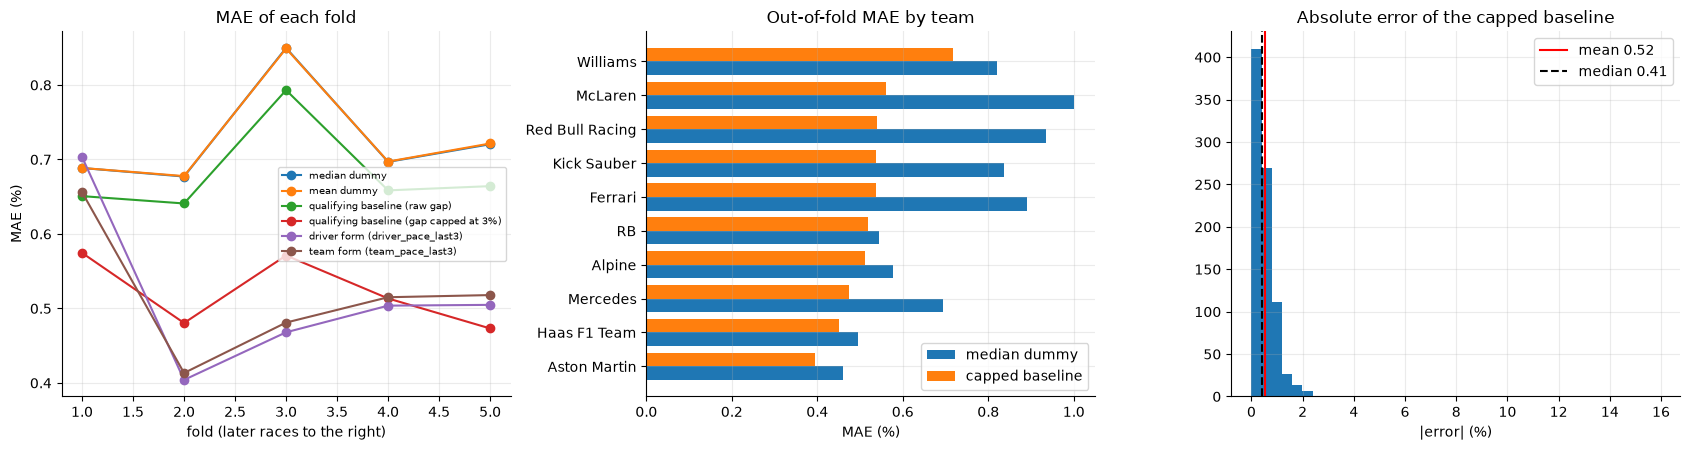

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(fold_mae))
for name in NAMES:
    ax[0].plot(x + 1, fold_mae[name], "o-", label=name)
ax[0].set(title="MAE of each fold", xlabel="fold (later races to the right)", ylabel="MAE (%)")
ax[0].legend(fontsize=7)
by_team = scored.groupby("team").agg(baseline=(base_col, "mean"), floor=(floor_col, "mean")).sort_values("baseline")
pos = np.arange(len(by_team))
ax[1].barh(pos - 0.2, by_team["floor"], 0.4, label="median dummy")
ax[1].barh(pos + 0.2, by_team["baseline"], 0.4, label="capped baseline")
ax[1].set(yticks=pos, yticklabels=by_team.index, title="Out-of-fold MAE by team", xlabel="MAE (%)")
ax[1].legend()
ax[2].hist(scored[base_col], bins=40)
ax[2].axvline(scored[base_col].mean(), color="r", label=f"mean {scored[base_col].mean():.2f}")
ax[2].axvline(scored[base_col].median(), color="k", ls="--", label=f"median {scored[base_col].median():.2f}")
ax[2].set(title="Absolute error of the capped baseline", xlabel="|error| (%)")
ax[2].legend()
plt.tight_layout()
plt.show()

## 4. Against the noise floor of `01`

`01_target` estimated the error no model can remove at about 0.23 to 0.40 MAE. The distance from the baseline to
that range is the room Phase 4 has.

In [7]:
floor_low, floor_high = 0.23, 0.40
mean_base = scored[base_col].mean()
print(
    f"capped baseline MAE {mean_base:.3f}; noise floor {floor_low}-{floor_high}; "
    f"room left: {mean_base - floor_high:.3f} to {mean_base - floor_low:.3f}"
)
print(f"median dummy MAE {scored[floor_col].mean():.3f}")

capped baseline MAE 0.522; noise floor 0.23-0.4; room left: 0.122 to 0.292
median dummy MAE 0.727


## Figures for the summary

In [8]:
FIGURES = ROOT / "docs" / "eda" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=100, bbox_inches="tight")
    plt.close(fig)
    print("saved", (FIGURES / name).relative_to(ROOT))


show = ["median dummy", base, "driver form (driver_pace_last3)", "team form (team_pace_last3)"]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
for name in show:
    ax[0].plot(np.arange(1, len(fold_mae) + 1), fold_mae[name], "o-", label=name)
ax[0].set(
    title="MAE of each validation fold (later races to the right)",
    xlabel="fold",
    ylabel="MAE (%)",
    xticks=range(1, len(fold_mae) + 1),
)
ax[0].legend(fontsize=7)
by_position = scored.groupby("qualifying position", observed=True)[["abs_error: " + n for n in show]].mean()
by_position.columns = show
by_position.plot.bar(ax=ax[1], rot=0, width=0.8)
ax[1].legend(fontsize=7)
ax[1].set(title="Out-of-fold MAE by qualifying position", xlabel="qualifying position", ylabel="MAE (%)")
save(fig, "09_baseline_cv.png")

saved docs/eda/figures/09_baseline_cv.png


## Findings

Numbers for Phase 4 to beat (validation: five expanding folds over whole races, MAE on valid rows only, 839 of 1,050 rows scored because the first 11 races only train):

| Predictor | CV MAE, mean ± sd over folds | Pooled, 95% interval over races |
| --- | --- | --- |
| Median dummy (the floor) | 0.727 ± 0.063 | 0.727 [0.66, 0.82] |
| Mean dummy | 0.727 ± 0.063 | 0.727 [0.66, 0.80] |
| Qualifying baseline, raw gap | 0.682 ± 0.056 | 0.682 [0.61, 0.76] |
| **Qualifying baseline, gap capped at 3%** | **0.523 ± 0.043** | **0.522 [0.47, 0.60]** |
| Driver form (`driver_pace_last3` as is) | 0.517 ± 0.100 | 0.516 [0.45, 0.60] |
| Team form (`team_pace_last3` as is) | 0.517 ± 0.079 | 0.516 [0.44, 0.59] |

With the 15-clean-lap minimum suggested in `02` the same figures are 0.703 (floor), 0.511 ± 0.039 (capped baseline), 0.494 ± 0.067 (driver form) and 0.493 ± 0.048 (team form).

Suggested decisions (they reach `DECISIONS.md` in step 13, after the review of the summary):

1. **The qualifying baseline reads the gap capped at 3%.** On the raw gap the contract's baseline scores 0.682, barely under the 0.727 floor; capped it scores 0.523 (gain over the floor +0.205 [+0.170, +0.241]; capped against raw +0.160 [+0.126, +0.197]). Without the cap in its definition, "MAE against the baseline" would be a very low bar. The numbers to record: baseline 0.523 ± 0.043 and floor 0.727 on all valid rows (0.511 and 0.703 with 15+ laps).
2. **Report MAE against a second reference, the driver's recent form.** Predicting `driver_pace_last3` unchanged scores the same as the capped baseline (difference -0.007 [-0.052, +0.043]) and costs nothing; the team form does the same. A model that only matches 0.52 adds nothing over a lookup of the last three races. This does not touch the promotion rule (0.98 × MAE against the champion over the last 5 races).

What the data says, with no decision attached:

- **The two references win in different places, so they are complementary.** Form beats the baseline in folds 2 and 3 (0.40 and 0.47 against 0.48 and 0.57), ties in fold 4 and loses in folds 1 and 5 (0.70 against 0.58 and 0.51 against 0.47). Fold 1 has only 11 races of history behind it. The spread of the form predictor over folds (0.10) is more than twice the baseline's (0.04). Combining them is the obvious room for the real models.
- **The baseline earns its gain at the front and the back of the grid.** By qualifying position its MAE against the floor is 0.50 against 0.98 for positions 1 to 5 and 0.50 against 0.77 for 16 to 20, but **0.54 against 0.54 for positions 6 to 10** and 0.56 against 0.60 for 11 to 15. The midfield is where the work is. By team the gain is large for Red Bull, McLaren and Ferrari (0.35 to 0.44) and almost nil for RB (0.03), Haas (0.04), Alpine and Aston Martin (0.07).
- **Rain in qualifying costs accuracy:** 0.66 in the 170 scored rows with rain against 0.49 without, and the gain over the floor shrinks from 0.22 to 0.13. Circuit type matters little (0.50 permanent, 0.55 hybrid, 0.58 street, on fewer rows).
- **The few rows under 15 clean laps move the figures.** They include the Zandvoort 2023 target (16.8%), which is scored in fold 1: the floor is 0.727 with all valid rows and 0.703 once the 15-lap minimum removes them, the capped baseline 0.523 and 0.511.
- **Room left:** the capped baseline is 0.12 to 0.29 above the 0.23–0.40 noise floor estimated in `01`.